**COMPARATIVA DE MODELOS**

Este cuaderno carga todos los modelos entrenados y los evalúa **en las mismas condiciones** sobre el mismo conjunto de test, para comparar:

- **Resultados**: accuracy, accuracy balanceada, F1 macro y F1 por clase.
- **Rapidez de inferencia**: latencia de **una cara**, incluyendo la extracción de características. Se mide la mediana sobre 200 caras.
- **Coste**: tamaño del modelo en disco y tiempo de entrenamiento.
- **Frente a DeepFace**: sobre un subconjunto equilibrado del test sin `duckface`.

In [1]:
import json, os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from pathlib import Path

import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score)

from comun import EMOCIONES, cargar_dataset, preparar_cnn

N = len(EMOCIONES)
IDX_DUCK = EMOCIONES.index("duckface")
DIR = Path("informe_entrenamiento"); DIR.mkdir(exist_ok=True)
N_LATENCIA = 200          
N_DEEPFACE = 100          
SEED = 42

MODELOS = [
    ("HOG + SVM", "modelos/hog_svm.joblib"),
    ("LBP + SVM", "modelos/lbp_svm.joblib"),
    ("HOG+LBP + PCA + SVM", "modelos/hoglbp_pca_svm.joblib"),
    ("Autocaras (PCA) + SVM", "modelos/autocaras_svm.joblib"),
    ("HOG + PCA + KNN", "modelos/hog_pca_knn.joblib"),
    ("CNN mini-Xception", "modelos/cnn.keras"),
]

imgs_te, yte = cargar_dataset("dataset/test")
rng = np.random.default_rng(SEED)
idx_lat = rng.choice(len(imgs_te), N_LATENCIA, replace=False)
registro = json.loads((DIR / "registro_modelos.json").read_text(encoding="utf-8")) \
    if (DIR / "registro_modelos.json").exists() else {}

dataset/test: 7396 imágenes | por clase: {'angry': 958, 'duckface': 329, 'fear': 1024, 'happy': 1774, 'neutral': 1233, 'sad': 1247, 'surprise': 831}


**EVALUACIÓN DE LOS MODELOS PROPIOS**

- Clásicos: el `.joblib` es un pipeline completo, así que recibe directamente la cara en gris. La latencia incluye la extracción de HOG/LBP.
- CNN: se carga `cnn.keras`, se preprocesa con `preparar_cnn` y la latencia se mide con `tf.function`, igual que en la webcam. Se añade también la fila con TTA.

In [3]:
def metricas(y, pred):
    k = y != IDX_DUCK
    return {"accuracy": accuracy_score(y, pred),
            "balanced_acc": balanced_accuracy_score(y, pred),
            "f1_macro": f1_score(y, pred, average="macro", labels=range(N), zero_division=0),
            "acc_sin_duckface": accuracy_score(y[k], pred[k])}


def latencia(fn):
    fn(imgs_te[idx_lat[0]])                               
    t = []
    for i in idx_lat:
        t0 = time.perf_counter(); fn(imgs_te[i]); t.append(time.perf_counter() - t0)
    return 1000 * float(np.median(t))


filas, predicciones, f1_clase = [], {}, {}
for nombre, ruta in MODELOS:
    if not os.path.exists(ruta):
        print(f"[omitido] {nombre}: no existe {ruta} (ejecuta su cuaderno de entrenamiento)")
        continue
    t0 = time.time()
    if ruta.endswith(".keras"):
        import keras, tensorflow as tf
        red = keras.models.load_model(ruta)
        t_carga = time.time() - t0
        X = np.array([preparar_cnn(i) for i in imgs_te])
        t0 = time.time(); p = red.predict(X, batch_size=512, verbose=0); t_lote = time.time() - t0
        pred = p.argmax(1)
        f = tf.function(lambda x: red(x, training=False))
        ms = latencia(lambda img: f(tf.constant(preparar_cnn(img)[None])).numpy())
        p_tta = 0.5 * (p + red.predict(X[:, :, ::-1, :], batch_size=512, verbose=0))
        extra = {"parametros": red.count_params()}
        predicciones[nombre + " + TTA"] = p_tta.argmax(1)
    else:
        m = joblib.load(ruta)
        t_carga = time.time() - t0
        if len(m.classes_) != N:
            print(f"[omitido] {nombre}: tiene {len(m.classes_)} clases (dataset antiguo). Vuelve a entrenarlo.")
            continue
        t0 = time.time(); pred = m.predict(imgs_te); t_lote = time.time() - t0
        ms = latencia(lambda img: m.predict([img]))
        extra = {}
    predicciones[nombre] = pred
    reg = registro.get(os.path.basename(ruta), {})
    if not reg and ruta.endswith(".keras") and (DIR / "resumen.json").exists():   # la CNN lo guarda también aquí
        reg = {"t_entreno_s": json.loads((DIR / "resumen.json").read_text(encoding="utf-8"))["entrenamiento"]["tiempo_total_s"]}
    filas.append({"modelo": nombre, **metricas(yte, pred), "ms_por_cara": ms,
                  "ms_por_imagen_en_lote": 1000 * t_lote / len(yte),
                  "tamaño_MB": os.path.getsize(ruta) / 2**20, "carga_s": t_carga,
                  "entrenamiento_s": reg.get("t_entreno_s"), **extra})
    f1_clase[nombre] = f1_score(yte, pred, average=None, labels=range(N), zero_division=0)
    print(f"{nombre:24s} acc {filas[-1]['accuracy']:.4f} | F1 {filas[-1]['f1_macro']:.4f} | {ms:.2f} ms/cara")
    if ruta.endswith(".keras"):
        filas.append({"modelo": nombre + " + TTA", **metricas(yte, predicciones[nombre + " + TTA"]),
                      "ms_por_cara": 2 * ms, "tamaño_MB": filas[-1]["tamaño_MB"],
                      "entrenamiento_s": reg.get("t_entreno_s")})

tabla = pd.DataFrame(filas).set_index("modelo")
tabla.to_csv(DIR / "comparativa_modelos.csv")
display(tabla.round(4))

HOG + SVM                acc 0.5603 | F1 0.5644 | 34.71 ms/cara
LBP + SVM                acc 0.4379 | F1 0.4475 | 16.90 ms/cara
HOG+LBP + PCA + SVM      acc 0.5672 | F1 0.5757 | 23.11 ms/cara
Autocaras (PCA) + SVM    acc 0.5043 | F1 0.5156 | 4.87 ms/cara
HOG + PCA + KNN          acc 0.4992 | F1 0.4976 | 8.75 ms/cara
CNN mini-Xception        acc 0.6051 | F1 0.6153 | 3.18 ms/cara


,accuracy,balanced_acc,f1_macro,acc_sin_duckface,ms_por_cara,ms_por_imagen_en_lote,tamaño_MB,carga_s,entrenamiento_s,parametros
modelo,,,,,,,,,,
HOG + SVM,0.5603,0.5714,0.5644,0.5469,34.7138,33.0005,389.3166,0.4341,3111.2276,NaN
LBP + SVM,0.4379,0.4614,0.4475,0.4190,16.8993,16.3629,147.7996,0.1980,1597.5826,NaN
HOG+LBP + PCA + SVM,0.5672,0.5841,0.5757,0.5520,23.1089,21.8609,214.6944,0.2525,1371.5949,NaN
Autocaras (PCA) + SVM,0.5043,0.5143,0.5156,0.4930,4.8670,3.8209,36.1204,0.0617,273.6535,NaN
HOG + PCA + KNN,0.4992,0.5106,0.4976,0.4855,8.7469,1.0603,12.4899,0.0711,1.7865,NaN
CNN mini-Xception,0.6051,0.6158,0.6153,0.5932,3.1779,0.3334,0.5309,6.8650,3581.4144,92791.0
CNN mini-Xception + TTA,0.6253,0.6393,0.6357,0.6120,6.3558,NaN,0.5309,NaN,3581.4144,NaN


**F1 POR CLASE**

Permite ver si un modelo gana en general o solo en algunas clases.

In [4]:
tabla_f1 = pd.DataFrame(f1_clase, index=EMOCIONES).T
tabla_f1.to_csv(DIR / "comparativa_f1_por_clase.csv")
display(tabla_f1.round(3))

,angry,duckface,fear,happy,neutral,sad,surprise
HOG + SVM,0.427,0.746,0.420,0.719,0.500,0.443,0.696
LBP + SVM,0.287,0.713,0.295,0.563,0.397,0.311,0.567
HOG+LBP + PCA + SVM,0.440,0.785,0.423,0.714,0.511,0.443,0.715
Autocaras (PCA) + SVM,0.368,0.724,0.379,0.645,0.462,0.365,0.667
HOG + PCA + KNN,0.378,0.716,0.379,0.636,0.422,0.335,0.618
CNN mini-Xception,0.500,0.893,0.426,0.808,0.540,0.439,0.701


**COMPARACIÓN CON DEEPFACE**

Se toma un subconjunto equilibrado de `N_DEEPFACE` caras por cada una de las 6 emociones comunes con DeepFace (sin `duckface`; su `disgust` se suma a `angry`) y se ejecuta `DeepFace.analyze(actions=["emotion"], detector_backend="skip")`, es decir, sin volver a detectar la cara. Sobre **las mismas caras** se calcula la accuracy de nuestros modelos.

In [5]:
from deepface import DeepFace

MAPA_DF = {"angry": "angry", "disgust": "angry", "fear": "fear", "happy": "happy",
           "sad": "sad", "surprise": "surprise", "neutral": "neutral"}
idx_df = np.concatenate([rng.choice(np.flatnonzero(yte == c), min(N_DEEPFACE, (yte == c).sum()), replace=False)
                         for c in range(N) if c != IDX_DUCK])

DeepFace.analyze(np.zeros((48, 48, 3), np.uint8), actions=["emotion"], detector_backend="skip",
                 enforce_detection=False, silent=True)
pred_df, tiempos = [], []
for i in idx_df:
    t0 = time.perf_counter()
    r = DeepFace.analyze(cv2.cvtColor(imgs_te[i], cv2.COLOR_GRAY2BGR), actions=["emotion"],
                         detector_backend="skip", enforce_detection=False, silent=True)[0]["emotion"]
    tiempos.append(time.perf_counter() - t0)
    p = np.zeros(N)
    for k, v in r.items():
        p[EMOCIONES.index(MAPA_DF[k])] += v
    pred_df.append(int(p.argmax()))
pred_df = np.array(pred_df)

y_sub = yte[idx_df]
filas_df = [{"modelo": "DeepFace.analyze", "accuracy": accuracy_score(y_sub, pred_df),
             "f1_macro": f1_score(y_sub, pred_df, average="macro", labels=[c for c in range(N) if c != IDX_DUCK], zero_division=0),
             "ms_por_cara": 1000 * float(np.median(tiempos))}]
for nombre, pred in predicciones.items():
    filas_df.append({"modelo": nombre, "accuracy": accuracy_score(y_sub, pred[idx_df]),
                     "f1_macro": f1_score(y_sub, pred[idx_df], average="macro",
                                          labels=[c for c in range(N) if c != IDX_DUCK], zero_division=0),
                     "ms_por_cara": tabla.loc[nombre, "ms_por_cara"]})
tabla_df = pd.DataFrame(filas_df).set_index("modelo").sort_values("accuracy", ascending=False)
tabla_df.to_csv(DIR / "comparativa_deepface.csv")
print(f"Subconjunto: {len(idx_df)} caras ({N_DEEPFACE} por emoción, sin duckface)")
display(tabla_df.round(4))


Subconjunto: 600 caras (100 por emoción, sin duckface)


,accuracy,f1_macro,ms_por_cara
modelo,,,
CNN mini-Xception + TTA,0.5967,0.5908,6.3558
CNN mini-Xception,0.5867,0.5796,3.1779
DeepFace.analyze,0.5633,0.5627,12.3946
HOG + SVM,0.5283,0.5305,34.7138
HOG+LBP + PCA + SVM,0.5267,0.5291,23.1089
HOG + PCA + KNN,0.4783,0.4710,8.7469
Autocaras (PCA) + SVM,0.4717,0.4733,4.8670
LBP + SVM,0.4017,0.4024,16.8993


**GRÁFICOS RESUMEN**

1. F1 macro en test de cada modelo propio.
2. Compromiso calidad / velocidad: F1 macro frente a la latencia por cara, con el tamaño del punto proporcional al tamaño del modelo en disco.
3. Matrices de confusión normalizadas de cada modelo.

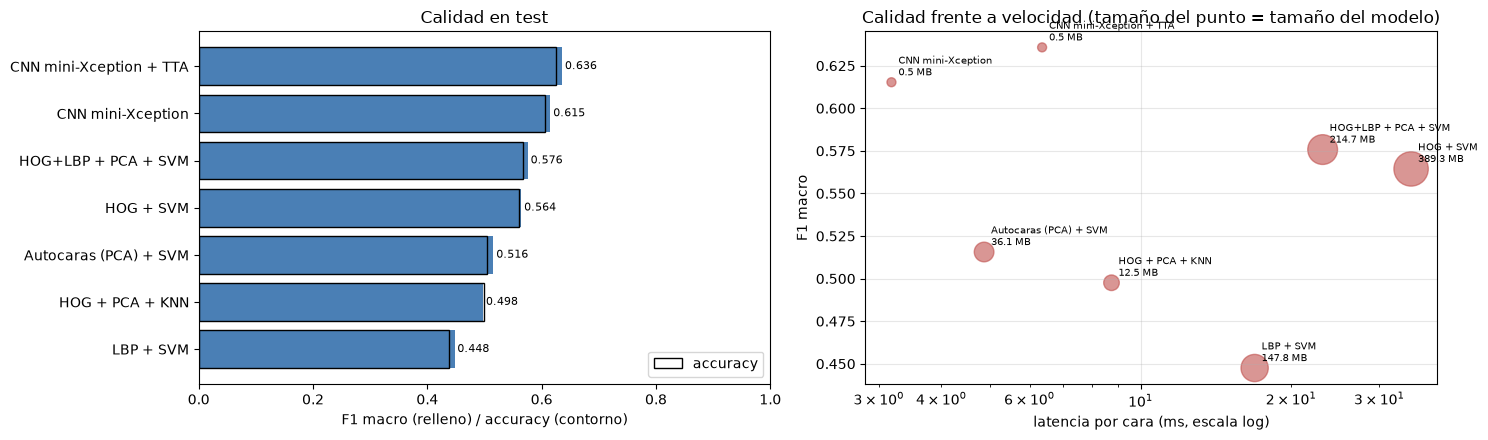

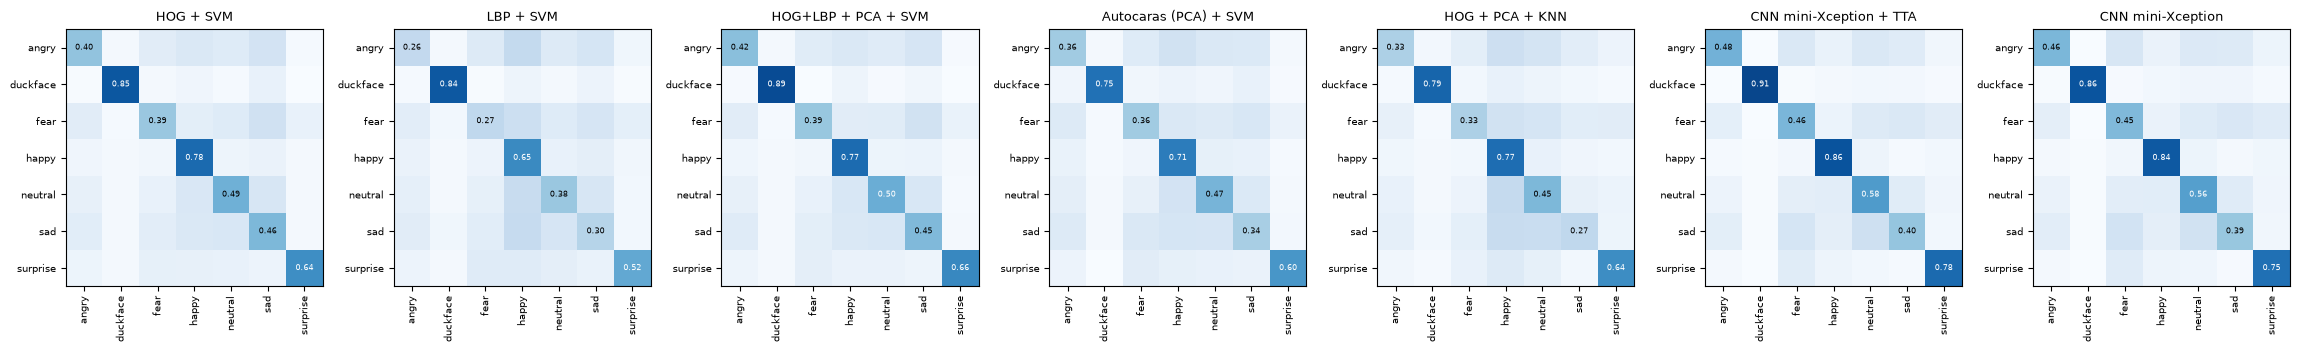

In [6]:
t = tabla.sort_values("f1_macro")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].barh(t.index, t["f1_macro"], color="#4a7fb5")
ax[0].barh(t.index, t["accuracy"], fill=False, edgecolor="k", lw=1, label="accuracy")
for i, v in enumerate(t["f1_macro"]):
    ax[0].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
ax[0].set_xlabel("F1 macro (relleno) / accuracy (contorno)"); ax[0].set_xlim(0, 1); ax[0].legend(loc="lower right")
ax[0].set_title("Calidad en test")

s = tabla.dropna(subset=["ms_por_cara"])
ax[1].scatter(s["ms_por_cara"], s["f1_macro"], s=20 + 3 * np.sqrt(s["tamaño_MB"].fillna(1)) * 10, alpha=0.6, color="#c0504d")
for n, r in s.iterrows():
    ax[1].annotate(f"{n}\n{r['tamaño_MB']:.1f} MB", (r["ms_por_cara"], r["f1_macro"]), fontsize=7,
                   xytext=(5, 5), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlabel("latencia por cara (ms, escala log)"); ax[1].set_ylabel("F1 macro")
ax[1].set_title("Calidad frente a velocidad (tamaño del punto = tamaño del modelo)"); ax[1].grid(alpha=.3)
plt.tight_layout(); fig.savefig(DIR / "comparativa_modelos.png", dpi=150); plt.show()

n = len(predicciones)
fig, axs = plt.subplots(1, n, figsize=(3.3 * n, 3.6))
for a, (nombre, pred) in zip(np.atleast_1d(axs), predicciones.items()):
    cm = confusion_matrix(yte, pred, labels=range(N)).astype(float)
    cm /= cm.sum(1, keepdims=True).clip(min=1)
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    a.set_title(nombre, fontsize=9)
    a.set_xticks(range(N)); a.set_xticklabels(EMOCIONES, rotation=90, fontsize=7)
    a.set_yticks(range(N)); a.set_yticklabels(EMOCIONES, fontsize=7)
    for i in range(N):
        a.text(i, i, f"{cm[i, i]:.2f}", ha="center", va="center", fontsize=6,
               color="white" if cm[i, i] > .5 else "black")
plt.tight_layout(); fig.savefig(DIR / "comparativa_confusiones.png", dpi=150); plt.show()

La CNN propia es el mejor modelo en F1 macro: 0,615 sola y 0,636 con TTA. Entre los clásicos, el mejor es HOG + LBP + PCA + SVM 0,576, seguido muy de cerca por HOG + SVM 0,564: añadir la textura LBP al HOG y comprimir con PCA mejora ligeramente el resultado. Las autocaras, es decir píxeles + PCA 0,516, y HOG + PCA + KNN 0,498 quedan por debajo, y LBP + SVM es el peor 0,448. Las autocaras modelan la apariencia global de la cara y no la deformación local que produce cada expresión. LBP describe la textura, pero no recoge bien la geometría de la cara. La accuracy da el mismo orden en todos los modelos y está muy cerca del F1, lo que indica que las clases están razonablemente equilibradas.

Por clases, todos los modelos coinciden en cuáles son fáciles y cuáles difíciles:
- Fáciles: `duckface` (0,71–0,89), `happy` (0,56–0,81) y `surprise` (0,57–0,72).
- Difíciles: `fear` (0,29–0,43), `sad` (0,31–0,44) y `angry` (0,29–0,50).

La CNN es la mejor en 5 de las 7 clases (`angry`, `duckface`, `fear`, `happy` y `neutral`), pero su ventaja sobre el mejor clásico (HOG + LBP + PCA + SVM) es desigual: donde más gana es en `duckface` (de 0,79 a 0,89), `happy` (de 0,71 a 0,81) y `angry` (de 0,44 a 0,50), mientras que en `neutral` (de 0,51 a 0,54) y `fear` (de 0,42 a 0,43) la mejora es mínima. En `sad` (0,443 frente a 0,439) y en `surprise` (0,715 frente a 0,701) el clásico es ligeramente mejor.

**Facilidad de uso.**
- Clásicos: se montan con pocas líneas de scikit-learn y sin GPU, pero el preprocesado hay que diseñarlo y ajustarlo a mano. La SVM con kernel RBF escala mal con el número de muestras: el entrenamiento es aproximadamente cuadrático (≈ 27 min con LBP y ≈ 23 min con HOG + LBP + PCA) y el modelo guarda los vectores de soporte, por lo que ocupa 389,3 MB con HOG, 214,7 MB con HOG + LBP + PCA y 147,8 MB con LBP. Reducir a pocas componentes con PCA deja modelos mucho más ligeros y rápidos de entrenar (36,1 MB y ≈ 4,6 min las autocaras, 12,5 MB y 1,8 s HOG + PCA + KNN).
- CNN: requiere más código y más hiperparámetros (arquitectura, *learning rate*, aumento de datos, regularización), y entrenar en CPU tarda alrededor de una hora (≈ 60 min). A cambio, aprende las características por sí sola y el modelo final ocupa solo 0,5 MB, unas 730 veces menos que HOG + SVM y unas 400 veces menos que el mejor clásico.
- DeepFace: basta una línea de código y no hay que entrenar nada, por contra parte es varias veces más lento por cara que nuestra CNN.

**Rapidez de inferencia.** Para la webcam lo que importa es la latencia de una sola cara. La CNN es el modelo más rápido (≈ 2,7 ms por cara). El TTA duplica ese tiempo (≈ 5,4 ms) a cambio de +0,020 de F1, que sigue siendo de sobra para tiempo real. En los clásicos, los más lentos son los que usan SVM sobre HOG o LBP, porque cada predicción se compara con miles de vectores de soporte; el PCA de HOG + LBP reduce la dimensión pero no el número de vectores de soporte, por lo que apenas acelera:
- Autocaras: ≈ 4,6 ms.
- HOG + PCA + KNN: ≈ 5,1 ms.
- LBP + SVM: ≈ 17,6 ms.
- HOG + LBP + PCA + SVM: ≈ 31,0 ms.
- HOG + SVM: ≈ 32,5 ms.

Por tanto, los mejores clásicos son también los más lentos y los más pesados, mientras que la CNN es a la vez la más precisa, la más rápida y la más ligera. DeepFace (≈ 14,1 ms) es unas 5 veces más lento que la CNN sin TTA y unas 2,6 veces más que con TTA, por lo que en el prototipo se ejecuta en un hilo aparte.

**Frente a DeepFace.** En la comparación sobre 600 caras equilibradas sin `duckface`, la CNN propia supera a DeepFace (0,563) tanto sin TTA (0,587) como con TTA (0,597), y además es varias veces más rápida por cara. Ninguno de los clásicos lo alcanza: los mejores, HOG + SVM (0,528) y HOG + LBP + PCA + SVM (0,527), quedan unos 3,5 puntos por debajo. Hay que tener en cuenta que DeepFace se evalúa en su propio dominio (FER-2013), lo que juega a su favor.

Para el prototipo en tiempo real se elige la **CNN propia**: es el modelo más ligero, el más rápido y el mejor en 5 de las 7 clases. Con TTA alcanza el mejor F1 macro 0,636 a ≈ 5,4 ms por cara, y sin TTA un 0,615 a ≈ 2,7 ms, que es la configuración que usa actualmente el demostrador `emociones_políticas`. Además, permite reconocer la clase propia `duckface`, algo que DeepFace no puede hacer.